# Assignemnt 3: ANN analysis

## Problem statement:
Finding the stored vectors closest to a query is the core step of dense retrieval. Doing it exactly means comparing the query against every vector, which gets too slow at scale. Approximate nearest neighbour (ANN) indexes are much faster, at the price of sometimes missing a true neighbour. In this assignment you will measure that trade-off yourself. You will benchmark three popular index types, HNSW, IVF-Flat and IVF-PQ, on two public datasets, run one experiment of your choice from a short list, carry out one open-ended experiment of your own on data you generate, and write a short report explaining what you found. We care about careful measurement and clear explanations, not about which index turns out fastest.


## Index Type 1: HNSW
HNSW (Hierarchical Navigable Small World) is a graph-based index that organizes vectors in a multi-layered graph structure. It allows for efficient nearest neighbor search by navigating through the graph layers, starting from a high-level overview and progressively refining the search in lower layers. HNSW is known for its high recall and low latency, making it suitable for large-scale retrieval tasks.

The logic behind HNSW is that it builds a small-world graph where each node (vector) is connected to a limited number of neighbors. During the search process, the algorithm starts from an entry point and traverses the graph, exploring neighboring nodes to find the closest vectors to the query. The hierarchical structure allows for efficient pruning of the search space, leading to faster retrieval times compared to exhaustive search methods.

The implementation of HNSW typically involves parameters such as the **number of layers**, **the number of connections per node**, and the **search depth**. These parameters can be tuned to balance between search speed and accuracy, depending on the specific requirements of the application.

## Measurement protocol (identical for all three indexes)

The same rules as in the IVF-Flat and IVF-PQ notebooks are used, implemented once in `ann_utils.py`.

| Item | Rule used |
|---|---|
| Quality | **recall@10**, tie-aware, against the FAISS exact reference |
| Speed | **queries per second, one query per `search()` call, one thread**, 3 repeats, **median** |
| Sweep | the search-time parameter, here **`efSearch`**, is increased until recall reaches about 0.99, **or until recall stops improving** (a plateau means the graph, not the search budget, is the limit) |
| Recall vs timing | recall on all 10,000 queries (one batched call, results do not depend on batching); timing on the first 500 queries |
| Baseline | exact FAISS search measured with the same single-query, single-thread protocol |

Two points specific to HNSW:
- **Building is the expensive part.** Every vector is inserted into the graph by searching the graph itself, so building 1M vectors takes minutes per index even with all CPU threads. Build time is reported together with the thread count.
- **Parallel construction is not deterministic.** With several threads, vectors are inserted in an interleaved order that differs from run to run, so two builds with the same settings give slightly different graphs. Try 1b therefore rebuilds the base configuration once more, to measure that noise before any difference between Tries is interpreted.

In [1]:
"""
This cell imports the shared helpers (ann_utils.py), sets the experiment configuration, loads both datasets with their exact reference results and measures the exact-search baseline with the single-query, single-thread protocol. No index is built yet.
"""

import gc
import time

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ann_utils import (K, DATASETS, MAX_THREADS, Evaluator, faiss_metric, build_record,
                       run_sweep, set_efsearch, exact_baseline_single_thread,
                       best_at_recall, qps_table, build_table, plot_tradeoff, save_df, int_cols)

# ---- experiment configuration -------------------------------------------------------------
N_TIME_Q = 500        # queries timed per repeat (the first 500 test queries)
REPS = 3              # repeats per timing; the median QPS is reported
STOP_RECALL = 0.99    # stop a sweep once recall reaches this
SEED = 1234
# efSearch below k = 10 behaves like k, so the sweep starts at 10
EFSEARCH_GRID = [10, 12, 16, 20, 24, 32, 40, 48, 64, 80, 96, 128, 192, 256, 384, 512, 768, 1024]

M_BASE, M_SMALL, M_LARGE = 16, 8, 32            # links per node (level 0 holds up to 2M)
EFC_BASE, EFC_LOW, EFC_HIGH = 100, 40, 200      # efConstruction

# ---- data, reference and exact baseline ---------------------------------------------------
EVAL = {name: Evaluator(name) for name in DATASETS}
BASELINE = {name: exact_baseline_single_thread(EVAL[name]) for name in DATASETS}

RESULTS, BUILDS = [], []

rows = []
for name, ev in EVAL.items():
    rows.append({"dataset": name, "metric": ev.metric, "N": f"{ev.n:,}", "dim": ev.d,
                 "reference": ev.ref_source, "exact bytes/vector": 4 * ev.d,
                 "exact QPS (1 query, 1 thread)": round(BASELINE[name]["qps"], 1)})
print(f"FAISS {faiss.__version__} | threads available for building: {MAX_THREADS} | timing: 1 thread")
print(int_cols(pd.DataFrame(rows)).to_string(index=False))

Loading sift dataset from ./data/raw/sift-128-euclidean.hdf5 (metric=l2)
Loading glove dataset from ./data/raw/glove-100-angular.hdf5 (metric=angular)
FAISS 1.15.1 | threads available for building: 20 | timing: 1 thread
dataset  metric         N  dim                    reference  exact bytes/vector  exact QPS (1 query, 1 thread)
   sift      l2 1,000,000  128 faiss exact (data/processed)                 512                           29.7
  glove angular 1,183,514  100 faiss exact (data/processed)                 400                           32.6


## What HNSW is made of, and what each part costs

HNSW does not partition the data. It builds a **graph** in which every vector is a node linked to a few nearby vectors, and a query finds its neighbours by **walking** through that graph.

| Component | Knob | What it controls | What it costs |
|---|---|---|---|
| **Links per node** | `M` | connectivity: each node keeps up to `2M` links on layer 0 and `M` on upper layers | memory (`~ 8M` bytes per vector for the links), build time, and the work per step of a search (more links to check) |
| **Layers** | automatic | each node gets a random top layer; layer `l` holds roughly `N / M^l` nodes, so the upper layers are tiny "express roads" | a few bytes per vector |
| **Construction search** | `efConstruction` | how many candidates are considered when a new vector chooses its links, i.e. **graph quality** | build time only (it does **not** change the index size) |
| **Link selection** | built in | a heuristic keeps links that point in *different* directions rather than the nearest ones only, so the graph stays navigable | nothing extra |
| **Query search** | `efSearch` | size of the candidate list of the best-first search on layer 0, the speed/recall dial | query time grows roughly linearly with it |
| **Storage** | "Flat" = raw float32 vectors | distances along the walk are **exact** | memory `4d` bytes per vector on top of the links |

**How a query works.** The search starts at the single entry point on the top layer and moves greedily to the closest node it can reach, layer by layer, which brings it close to the query in a handful of steps. On layer 0 it switches to a best-first search that keeps `efSearch` candidates and expands the best unexplored one until no candidate can be improved. The top 10 candidates are returned.

**Cost model.** The work per query is about `efSearch x (links per node)` distance computations, which depends on the graph and `efSearch` but hardly on `N` (the walk grows roughly with `log N`). IVF, by contrast, scans a *fixed fraction* of the database, so its work grows linearly with `N`. This is why HNSW compares only a tiny share of the database per query, and also why it needs **more memory** (links) and **a much longer build**.

**Why HNSW can fail.** Distances are exact, so a true neighbour is missed only if the walk never reaches it: the search ends in a region of the graph that does not lead to it (too small `efSearch`), or the graph itself has weak or missing paths to it (too few links or poor construction). Both are tested below.

Each Try changes **one thing** relative to the base, so any change in the curves can be attributed to that component. Every Try has a markdown cell with the decision, the reasoning, the alternatives that were not chosen and a hypothesis to check against the output.

In [2]:
"""
This cell defines the helpers used by every Try. build_hnsw builds and times one index, graph_stats reads the layer sizes and the average number of links on layer 0 out of the finished graph, and run_try_hnsw builds the index for each dataset, records build statistics, sweeps efSearch with the single-query single-thread protocol and stores everything in RESULTS / BUILDS.
"""

def build_hnsw(ev, M, efc, sq8=False):
    if sq8:   # same graph, but vectors stored as 8-bit scalar-quantised codes (needs a training step)
        index = faiss.IndexHNSWSQ(ev.d, faiss.ScalarQuantizer.QT_8bit, M, faiss_metric(ev.metric))
        sample = ev.train[np.random.default_rng(SEED).choice(ev.n, min(100_000, ev.n), replace=False)]
        t0 = time.perf_counter(); index.train(sample); train_s = time.perf_counter() - t0
    else:
        index = faiss.IndexHNSWFlat(ev.d, M, faiss_metric(ev.metric))
        train_s = 0.0                                           # a graph over raw vectors needs no training
    index.hnsw.efConstruction = efc
    t0 = time.perf_counter(); index.add(ev.train); add_s = time.perf_counter() - t0       # builds the graph
    return index, train_s, add_s


def graph_stats(index):
    """Nodes per layer and the average number of links actually used on layer 0."""
    h = index.hnsw
    levels = faiss.vector_to_array(h.levels)                    # stores (top layer + 1) for each node
    layer_sizes = [int((levels > l).sum()) for l in range(h.max_level + 1)]
    cum = faiss.vector_to_array(h.cum_nneighbor_per_level).astype(np.int64)
    offs = faiss.vector_to_array(h.offsets).astype(np.int64)
    nbrs = faiss.vector_to_array(h.neighbors)
    width, n, filled = int(cum[1] - cum[0]), len(offs) - 1, 0
    for s in range(0, n, 200_000):
        idx = offs[s:min(s + 200_000, n), None] + np.arange(width)
        filled += int((nbrs[idx] >= 0).sum())
    return layer_sizes, filled / n


def run_try_hnsw(try_name, M, efc, sq8=False):
    print("=" * 100)
    print(try_name)
    for name in DATASETS:
        ev = EVAL[name]
        print(f"\n[{name}] building HNSW: M={M}, efConstruction={efc}, storage={'8-bit scalar quantised' if sq8 else 'flat float32'}"
              f" (this takes a while)")
        index, train_s, add_s = build_hnsw(ev, M, efc, sq8)
        layers, deg0 = graph_stats(index)
        rec = build_record(ev, index, name, "HNSW", try_name, f"M={M}, efConstruction={efc}, sq8={sq8}", train_s, add_s)
        rec.update(M=M, efC=efc, layers=" > ".join(f"{s:,}" for s in layers), n_layers=len(layers),
                   mean_links_layer0=deg0, is_variant=sq8)
        BUILDS.append(rec)
        print(f"[{name}] build: {train_s + add_s:.1f} s | size {rec['size_mb']:.0f} MB = {rec['bytes_per_vector']:.0f} bytes/vector "
              f"(raw vector {4 * ev.d if not sq8 else ev.d} B, the rest is the graph)")
        print(f"[{name}] nodes per layer (layer 0 first): {rec['layers']}")
        print(f"[{name}] layer 0 uses {deg0:.1f} of {2 * M} link slots per node on average")

        df = run_sweep(index, ev, set_efsearch, EFSEARCH_GRID, n_time_q=N_TIME_Q, reps=REPS,
                       stop_recall=STOP_RECALL, stats="hnsw", param_name="efSearch", label=f"[{name}] ")
        df.insert(0, "try", try_name); df.insert(0, "dataset", name); df.insert(0, "index", "HNSW")
        df["is_variant"] = sq8
        RESULTS.append(df)
        for t in (0.90, 0.95):
            b = best_at_recall(df, t)
            msg = (f"efSearch={int(b['param'])} (recall {b['recall']:.4f}, {b['qps']:.0f} QPS)" if b is not None
                   else f"NOT reached (max recall {df['recall'].max():.4f})")
            print(f"[{name}] recall >= {t}: {msg}")
        del index
        gc.collect()

print("helpers defined")

helpers defined


## Try 1: base configuration, `M = 16`, `efConstruction = 100`

**Decision.** 16 links per node (32 on layer 0), construction candidate list of 100, flat float32 storage, `efSearch` swept from 10 upwards.

**Reasoning.**
- `M = 16` is the most common default and sits in the middle of the sensible range (8 to 64). It is large enough for 100- to 128-dimensional data to be navigable and small enough that the links cost about 130 bytes per vector.
- `efConstruction = 100` is several times `M`, which is the usual rule of thumb for a decent graph; it keeps a 1M-vector build in the range of minutes rather than hours.
- It is the reference every other Try is compared with.

**Alternatives not chosen as the base.**
- *`M = 32` with `efConstruction = 200` (the setting often quoted for best quality):* better recall but roughly 4x the build time and 2x the link memory. It is tested separately (Try 3, Try 5) rather than assumed.
- *`M = 4` or `M = 6`:* graph is too sparse for high-dimensional data; the sweep would mainly show failures to connect.
- *Starting `efSearch` below 10:* FAISS needs at least `k = 10` candidates to return ten results, so values below 10 behave exactly like 10 and would add nothing.

**Hypothesis.** Recall rises steeply with the first few `efSearch` values and then flattens, while QPS falls roughly in proportion to `efSearch`. SIFT should reach 0.95 with a small `efSearch`; GloVe, which is a harder dataset for graph navigation, should need clearly more. The number of distances computed per query should be a tiny fraction of the database.

In [3]:
"""
Try 1: M = 16, efConstruction = 100. The base every other Try is compared with.
"""
run_try_hnsw("Try 1: M=16, efC=100 (base)", M_BASE, EFC_BASE)

Try 1: M=16, efC=100 (base)

[sift] building HNSW: M=16, efConstruction=100, storage=flat float32 (this takes a while)
[sift] build: 32.5 s | size 656 MB = 656 bytes/vector (raw vector 512 B, the rest is the graph)
[sift] nodes per layer (layer 0 first): 1,000,000 > 62,403 > 3,903 > 210 > 16 > 1
[sift] layer 0 uses 19.6 of 32 link slots per node on average
  [sift] efSearch=10    recall@10=0.7003 |  12875.8 QPS (  0.078 ms/q) | compared  0.04% of db
  [sift] efSearch=12    recall@10=0.7373 |  13630.1 QPS (  0.073 ms/q) | compared  0.04% of db
  [sift] efSearch=16    recall@10=0.7910 |  10673.5 QPS (  0.094 ms/q) | compared  0.05% of db
  [sift] efSearch=20    recall@10=0.8289 |   9863.9 QPS (  0.101 ms/q) | compared  0.06% of db
  [sift] efSearch=24    recall@10=0.8566 |  10050.4 QPS (  0.099 ms/q) | compared  0.06% of db
  [sift] efSearch=32    recall@10=0.8946 |   9196.7 QPS (  0.109 ms/q) | compared  0.08% of db
  [sift] efSearch=40    recall@10=0.9197 |   5499.7 QPS (  0.182 ms/q) 

## Try 1b: the same configuration rebuilt, to measure build noise

**Decision.** Build Try 1 a second time with identical settings.

**Reasoning.** Multi-threaded insertion makes the graph differ slightly from build to build. Before reading anything into the difference between, say, `efConstruction = 100` and `200`, we need to know how large the difference between two *identical* builds is. If Try 1 and Try 1b nearly coincide, differences between Tries are real; if they differ as much as two different settings, those settings cannot be separated by this experiment.

**Alternatives not chosen.**
- *Building with one thread for exact reproducibility:* a single-threaded build of 1M vectors takes many times longer, and real deployments build in parallel anyway.
- *Many repeats and error bars:* the right thing for a paper, but each repeat costs minutes of build time; one repeat is enough to see whether the noise is small or large.

**Hypothesis.** The two curves almost overlap. Differences of about one percent in recall at equal `efSearch` should be treated as noise.

In [4]:
"""
Try 1b: identical to Try 1, built again, as a noise check for the non-deterministic parallel build.
"""
run_try_hnsw("Try 1b: M=16, efC=100 (rebuild, noise check)", M_BASE, EFC_BASE)

Try 1b: M=16, efC=100 (rebuild, noise check)

[sift] building HNSW: M=16, efConstruction=100, storage=flat float32 (this takes a while)
[sift] build: 34.9 s | size 656 MB = 656 bytes/vector (raw vector 512 B, the rest is the graph)
[sift] nodes per layer (layer 0 first): 1,000,000 > 62,403 > 3,903 > 210 > 16 > 1
[sift] layer 0 uses 19.6 of 32 link slots per node on average
  [sift] efSearch=10    recall@10=0.7003 |  13679.7 QPS (  0.073 ms/q) | compared  0.04% of db
  [sift] efSearch=12    recall@10=0.7373 |  11679.7 QPS (  0.086 ms/q) | compared  0.04% of db
  [sift] efSearch=16    recall@10=0.7910 |  12244.5 QPS (  0.082 ms/q) | compared  0.05% of db
  [sift] efSearch=20    recall@10=0.8289 |   8226.2 QPS (  0.122 ms/q) | compared  0.06% of db
  [sift] efSearch=24    recall@10=0.8566 |   9840.1 QPS (  0.102 ms/q) | compared  0.06% of db
  [sift] efSearch=32    recall@10=0.8946 |   7085.3 QPS (  0.141 ms/q) | compared  0.08% of db
  [sift] efSearch=40    recall@10=0.9197 |   5890.2 QP

## Try 2: sparser graph, `M = 8`

**Decision.** Halve the links per node (8, and 16 on layer 0); everything else as the base.

**Reasoning.** This isolates the effect of connectivity. Fewer links mean less memory, a faster build and cheaper steps during the search (fewer neighbours to check per expanded node), but also fewer routes to reach any given vector.

**Alternatives not chosen.** `M = 4` (see Try 1) and `M = 12` (too close to 16 to rise above build noise measured in Try 1b).

**Hypothesis.** Lower recall at the same `efSearch`, and possibly a **recall ceiling** below 0.99 that raising `efSearch` cannot fix, because some true neighbours have no good path leading to them. Expect the ceiling to be lower on GloVe than on SIFT. QPS at equal `efSearch` should be higher than the base, so whether `M = 8` wins at a given recall target depends on how much extra `efSearch` it needs.

In [5]:
"""
Try 2: M = 8, efConstruction = 100.
"""
run_try_hnsw("Try 2: M=8 (sparser)", M_SMALL, EFC_BASE)

Try 2: M=8 (sparser)

[sift] building HNSW: M=8, efConstruction=100, storage=flat float32 (this takes a while)
[sift] build: 27.3 s | size 593 MB = 593 bytes/vector (raw vector 512 B, the rest is the graph)
[sift] nodes per layer (layer 0 first): 1,000,000 > 124,841 > 15,653 > 1,964 > 210 > 27 > 5 > 1
[sift] layer 0 uses 12.5 of 16 link slots per node on average
  [sift] efSearch=10    recall@10=0.5699 |  20115.5 QPS (  0.050 ms/q) | compared  0.02% of db
  [sift] efSearch=12    recall@10=0.6101 |  16623.4 QPS (  0.060 ms/q) | compared  0.03% of db
  [sift] efSearch=16    recall@10=0.6709 |  15456.0 QPS (  0.065 ms/q) | compared  0.03% of db
  [sift] efSearch=20    recall@10=0.7147 |  13916.2 QPS (  0.072 ms/q) | compared  0.04% of db
  [sift] efSearch=24    recall@10=0.7470 |  11639.7 QPS (  0.086 ms/q) | compared  0.04% of db
  [sift] efSearch=32    recall@10=0.7949 |  10592.7 QPS (  0.094 ms/q) | compared  0.05% of db
  [sift] efSearch=40    recall@10=0.8296 |   7176.3 QPS (  0.139 

## Try 3: denser graph, `M = 32`

**Decision.** Double the links per node (32, and 64 on layer 0); everything else as the base.

**Reasoning.** The opposite end of the connectivity axis. More links give the search more routes and make the graph more robust, so recall should be reached with a smaller `efSearch`. The price is about 250 extra bytes of links per vector, a longer build, and more distance computations per expanded node.

**Alternatives not chosen.** `M = 64`: link memory (about 520 bytes per vector) would exceed the size of the raw vector itself, the build becomes very slow, and the gain over `M = 32` is typically small. It would be worth testing only if `M = 32` still showed a ceiling.

**Hypothesis.** The highest recall at small `efSearch` of all Tries, but not necessarily the highest QPS at a given recall: each step now costs more, so there is a break-even between "fewer steps needed" and "more expensive steps". The interesting output is where that break-even falls for SIFT versus GloVe.

In [6]:
"""
Try 3: M = 32, efConstruction = 100.
"""
run_try_hnsw("Try 3: M=32 (denser)", M_LARGE, EFC_BASE)

Try 3: M=32 (denser)

[sift] building HNSW: M=32, efConstruction=100, storage=flat float32 (this takes a while)
[sift] build: 38.3 s | size 784 MB = 784 bytes/vector (raw vector 512 B, the rest is the graph)
[sift] nodes per layer (layer 0 first): 1,000,000 > 31,254 > 978 > 27 > 1
[sift] layer 0 uses 24.7 of 64 link slots per node on average
  [sift] efSearch=10    recall@10=0.7470 |  16681.0 QPS (  0.060 ms/q) | compared  0.05% of db
  [sift] efSearch=12    recall@10=0.7809 |  13003.6 QPS (  0.077 ms/q) | compared  0.06% of db
  [sift] efSearch=16    recall@10=0.8306 |   7442.6 QPS (  0.134 ms/q) | compared  0.07% of db
  [sift] efSearch=20    recall@10=0.8647 |   9731.9 QPS (  0.103 ms/q) | compared  0.07% of db
  [sift] efSearch=24    recall@10=0.8891 |   7352.1 QPS (  0.136 ms/q) | compared  0.08% of db
  [sift] efSearch=32    recall@10=0.9220 |   7481.2 QPS (  0.134 ms/q) | compared  0.10% of db
  [sift] efSearch=40    recall@10=0.9426 |   7191.9 QPS (  0.139 ms/q) | compared  0.1

## Try 4: cheaper construction, `efConstruction = 40`

**Decision.** Base `M = 16`, but each insertion considers only 40 candidates instead of 100.

**Reasoning.** `efConstruction` controls graph *quality* without changing graph *size*: the index file is the same size, only the choice of links is poorer. This makes it the cleanest way to see what build effort buys. It is also the tweak a practitioner reaches for first when the build is too slow.

**Alternatives not chosen.** `efConstruction = 16` (equal to `M`): the construction search could barely compare candidates and the graph would be close to random, which is not informative. `efConstruction = 20` and `30` are too close to 40 to separate from noise.

**Hypothesis.** The build is noticeably faster (roughly proportional to the candidate list size), index size is unchanged, and recall at the same `efSearch` is lower, so more `efSearch` (and hence a lower QPS) is needed to reach 0.90 and 0.95.

In [7]:
"""
Try 4: M = 16, efConstruction = 40.
"""
run_try_hnsw("Try 4: efC=40 (cheaper build)", M_BASE, EFC_LOW)

Try 4: efC=40 (cheaper build)

[sift] building HNSW: M=16, efConstruction=40, storage=flat float32 (this takes a while)
[sift] build: 12.6 s | size 656 MB = 656 bytes/vector (raw vector 512 B, the rest is the graph)
[sift] nodes per layer (layer 0 first): 1,000,000 > 62,403 > 3,903 > 210 > 16 > 1
[sift] layer 0 uses 14.6 of 32 link slots per node on average
  [sift] efSearch=10    recall@10=0.6279 |  22109.0 QPS (  0.045 ms/q) | compared  0.03% of db
  [sift] efSearch=12    recall@10=0.6647 |  25274.9 QPS (  0.040 ms/q) | compared  0.04% of db
  [sift] efSearch=16    recall@10=0.7215 |  20713.4 QPS (  0.048 ms/q) | compared  0.04% of db
  [sift] efSearch=20    recall@10=0.7621 |  17543.2 QPS (  0.057 ms/q) | compared  0.05% of db
  [sift] efSearch=24    recall@10=0.7921 |  15708.5 QPS (  0.064 ms/q) | compared  0.05% of db
  [sift] efSearch=32    recall@10=0.8344 |  12581.6 QPS (  0.079 ms/q) | compared  0.06% of db
  [sift] efSearch=40    recall@10=0.8655 |  11434.0 QPS (  0.087 ms/q)

## Try 5: more careful construction, `efConstruction = 200`

**Decision.** Base `M = 16`, with 200 candidates per insertion.

**Reasoning.** The other side of Try 4. Doubling the construction effort should give better links; this tests whether the base is already near the useful limit or still leaves recall on the table.

**Alternatives not chosen.** `efConstruction = 400` or higher: build time grows roughly in proportion and each extra doubling usually buys less. If Try 5 already shows only a small gain over Try 1, higher values would only confirm diminishing returns at a cost of tens of minutes per dataset.

**Hypothesis.** Longer build, identical size, recall at the same `efSearch` somewhat higher than the base, so a smaller `efSearch` reaches 0.95 and QPS at that recall improves. The gain from 100 to 200 should be smaller than from 40 to 100 (diminishing returns); compare with the noise seen in Try 1b to decide whether the gain is real.

In [8]:
"""
Try 5: M = 16, efConstruction = 200.
"""
run_try_hnsw("Try 5: efC=200 (careful build)", M_BASE, EFC_HIGH)

Try 5: efC=200 (careful build)

[sift] building HNSW: M=16, efConstruction=200, storage=flat float32 (this takes a while)
[sift] build: 55.8 s | size 656 MB = 656 bytes/vector (raw vector 512 B, the rest is the graph)
[sift] nodes per layer (layer 0 first): 1,000,000 > 62,403 > 3,903 > 210 > 16 > 1
[sift] layer 0 uses 22.1 of 32 link slots per node on average
  [sift] efSearch=10    recall@10=0.7165 |  23625.1 QPS (  0.042 ms/q) | compared  0.04% of db
  [sift] efSearch=12    recall@10=0.7542 |  21820.5 QPS (  0.046 ms/q) | compared  0.04% of db
  [sift] efSearch=16    recall@10=0.8084 |  18450.9 QPS (  0.054 ms/q) | compared  0.05% of db
  [sift] efSearch=20    recall@10=0.8466 |  15677.3 QPS (  0.064 ms/q) | compared  0.06% of db
  [sift] efSearch=24    recall@10=0.8744 |  13984.5 QPS (  0.072 ms/q) | compared  0.07% of db
  [sift] efSearch=32    recall@10=0.9117 |  11542.8 QPS (  0.087 ms/q) | compared  0.08% of db
  [sift] efSearch=40    recall@10=0.9345 |   9560.2 QPS (  0.105 ms/

## Try 6 (diagnostic): same graph, 8-bit scalar-quantised storage

**Decision.** Base `M = 16`, `efConstruction = 100`, but the vectors are stored as 8-bit codes (`IndexHNSWSQ`, one byte per dimension) instead of float32.

**Reasoning.** HNSW has two memory costs: the vectors and the links. This Try shrinks the first. It shows how much of the index size is raw vectors, and what compressing them does to recall, much as IVF-PQ compresses the vectors of IVF. Scalar quantisation is the gentlest compression (4x smaller vectors, small error), so it is the natural first step.

**Alternatives not chosen.**
- *`IndexHNSWPQ` (product quantisation of the vectors):* much smaller, but the graph is then built on heavily approximate distances and quality drops sharply; it needs its own tuning and belongs to the improvement part of the assignment.
- *Dropping the full vectors and re-ranking:* needs a second stage and the vectors again.

Because this index stores approximate vectors, it is **not** the HNSW index the assignment asks for. It is run as a diagnostic and **kept out of the main report curve** and tables (a second plot shows it for comparison).

**Hypothesis.** Index size drops by roughly `3d` bytes per vector (the graph does not shrink), build and search are of similar speed, and recall has a slightly lower ceiling than the flat version because distances are now approximate.

In [9]:
"""
Try 6 (diagnostic): M = 16, efConstruction = 100, vectors stored as 8-bit scalar-quantised codes. Tagged is_variant and kept out of the main report curve.
"""
run_try_hnsw("Try 6: 8-bit scalar-quantised vectors (diagnostic)", M_BASE, EFC_BASE, sq8=True)

Try 6: 8-bit scalar-quantised vectors (diagnostic)

[sift] building HNSW: M=16, efConstruction=100, storage=8-bit scalar quantised (this takes a while)
[sift] build: 56.6 s | size 272 MB = 272 bytes/vector (raw vector 128 B, the rest is the graph)
[sift] nodes per layer (layer 0 first): 1,000,000 > 62,403 > 3,903 > 210 > 16 > 1
[sift] layer 0 uses 19.4 of 32 link slots per node on average
  [sift] efSearch=10    recall@10=0.6973 |  10546.9 QPS (  0.095 ms/q) | compared  0.04% of db
  [sift] efSearch=12    recall@10=0.7353 |   9686.0 QPS (  0.103 ms/q) | compared  0.04% of db
  [sift] efSearch=16    recall@10=0.7890 |   8074.5 QPS (  0.124 ms/q) | compared  0.05% of db
  [sift] efSearch=20    recall@10=0.8256 |   7125.8 QPS (  0.140 ms/q) | compared  0.06% of db
  [sift] efSearch=24    recall@10=0.8518 |   5887.5 QPS (  0.170 ms/q) | compared  0.06% of db
  [sift] efSearch=32    recall@10=0.8885 |   5388.0 QPS (  0.186 ms/q) | compared  0.07% of db
  [sift] efSearch=40    recall@10=0.91

## Comparing the Tries: which component bought what?

For each dataset the table lists, per Try, the build time, the index size split into raw vectors and graph, the **recall ceiling** (the highest recall the sweep reached), and, for recall 0.90 and 0.95, the `efSearch` needed, the **number of distances computed per query** (as a percentage of the database) and the QPS.

How to read it:
- *Same `M`, different `efConstruction`* (Tries 1, 1b, 4, 5): build effort versus graph quality. Size must be unchanged.
- *Different `M`* (Tries 1, 2, 3): connectivity versus memory, build time and cost per step.
- *Distance computations per query* show the cost directly. Compare it with IVF-Flat, which had to compare several percent of the database for the same recall.
- *Hops per query* is the number of graph nodes expanded; distances per query divided by hops is roughly the number of links followed per step.
- The graph overhead column is the index size per vector minus the raw vector bytes: it is the price of the links.

In [10]:
"""
This cell compares all Tries: build time, size split into vectors and graph, recall ceiling, efSearch / distance computations / QPS at recall 0.90 and 0.95, and the structure of each graph (nodes per layer).
"""
RES = pd.concat(RESULTS, ignore_index=True)
BLD = pd.DataFrame(BUILDS)

for ds in DATASETS:
    ev = EVAL[ds]
    rows = []
    for tr, g in RES[RES["dataset"] == ds].groupby("try", sort=False):
        b = BLD[(BLD["dataset"] == ds) & (BLD["try"] == tr)].iloc[0]
        raw = ev.d if b["is_variant"] else 4 * ev.d
        row = {"try": tr, "build s": round(b["build_s"], 1), "bytes/vec": round(b["bytes_per_vector"]),
               "graph B/vec": round(b["bytes_per_vector"] - raw), "ceiling": round(g["recall"].max(), 4)}
        for t in (0.90, 0.95):
            r = best_at_recall(g, t)
            row[f"ef@{t}"] = int(r["param"]) if r is not None else None
            row[f"dists%@{t}"] = round(r["dist_comps_per_query"] / ev.n * 100, 3) if r is not None else None
            row[f"QPS@{t}"] = round(r["qps"], 1) if r is not None else None
        rows.append(row)
    print(f"\n===== {ds}: Tries side by side (exact baseline: {BASELINE[ds]['qps']:.1f} QPS, {4 * ev.d} bytes/vector) =====")
    print(int_cols(pd.DataFrame(rows)).to_string(index=False))

    print(f"\n----- {ds}: graph structure and work per query at recall 0.95 (or at the ceiling) -----")
    rows = []
    for tr, g in RES[RES["dataset"] == ds].groupby("try", sort=False):
        b = BLD[(BLD["dataset"] == ds) & (BLD["try"] == tr)].iloc[0]
        r = best_at_recall(g, 0.95)
        r = g.loc[g["recall"].idxmax()] if r is None else r
        rows.append({"try": tr, "links used L0": round(b["mean_links_layer0"], 1), "slots L0": 2 * int(b["M"]),
                     "at recall": round(r["recall"], 4), "efSearch": int(r["param"]),
                     "dists/query": int(r["dist_comps_per_query"]), "hops/query": int(r["hops_per_query"])})
    print(int_cols(pd.DataFrame(rows)).to_string(index=False))
    print("nodes per layer (layer 0 first), base:", BLD[(BLD["dataset"] == ds)].iloc[0]["layers"])


===== sift: Tries side by side (exact baseline: 29.7 QPS, 512 bytes/vector) =====
                                               try  build s  bytes/vec  graph B/vec  ceiling  ef@0.9  dists%@0.9  QPS@0.9  ef@0.95  dists%@0.95  QPS@0.95
                       Try 1: M=16, efC=100 (base)     32.5        656          144   0.9930      40       0.088   5499.7       64        0.124    4063.6
      Try 1b: M=16, efC=100 (rebuild, noise check)     34.9        656          144   0.9930      40       0.088   5890.2       64        0.124    4730.8
                              Try 2: M=8 (sparser)     27.3        593           81   0.9926      80       0.092   5428.4      192        0.186    2455.0
                              Try 3: M=32 (denser)     38.3        784          272   0.9916      32       0.099   7481.2       48        0.131    5727.4
                     Try 4: efC=40 (cheaper build)     12.6        656          144   0.9931      64       0.102   7579.1      128        0.175    

## Report item 1: recall@10 against queries per second

Same layout as in the other notebooks: thin lines are the individual build settings, the bold black line is the best trade-off curve, the red star is exact FAISS search (same single-query, single-thread protocol). The main figure uses **only the flat-storage HNSW settings (Tries 1 to 5, including the rebuild)**, because that is the index the assignment asks for. The second figure adds the scalar-quantised variant (Try 6).

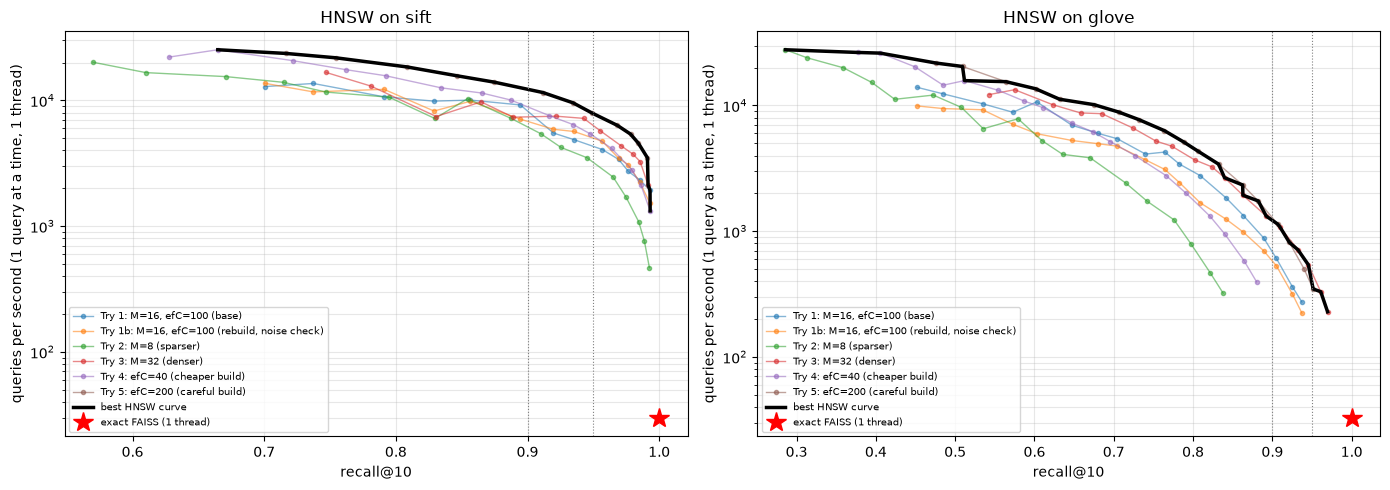

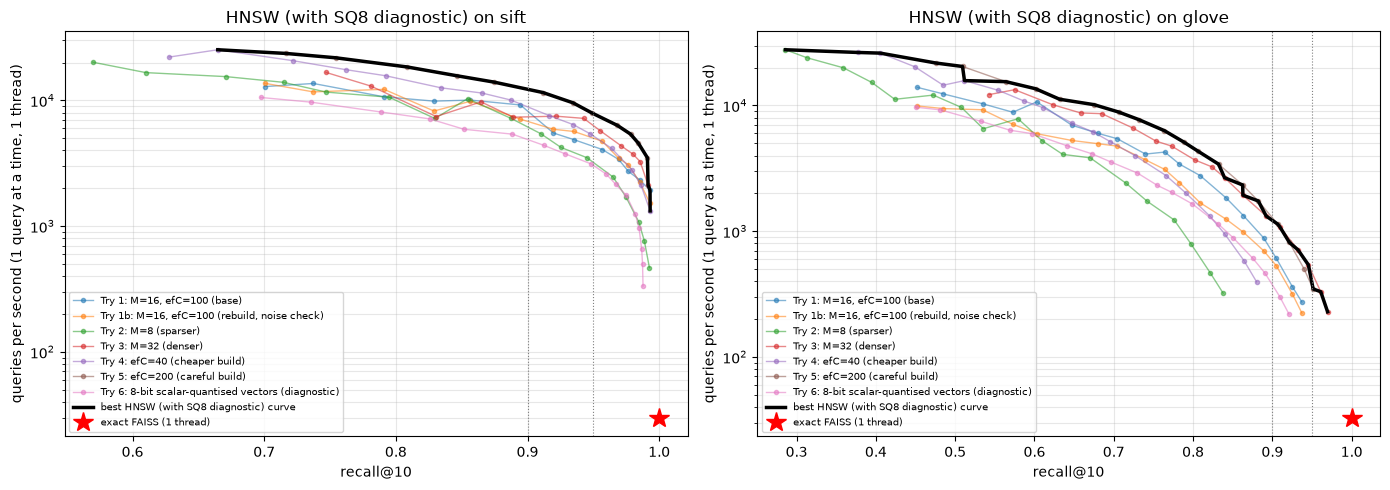

In [11]:
"""
This cell plots recall@10 against QPS for the flat-storage HNSW settings (the curve used in the report) and then again including the scalar-quantised diagnostic (Try 6). Both figures are saved to data/processed/plots.
"""
RES_MAIN = RES[~RES["is_variant"]]
BLD_MAIN = BLD[~BLD["is_variant"]]
fig = plot_tradeoff(RES_MAIN, BASELINE, "HNSW", "./data/processed/plots/hnsw_tradeoff.png")
plt.show()

fig = plot_tradeoff(RES, BASELINE, "HNSW (with SQ8 diagnostic)", "./data/processed/plots/hnsw_with_sq8.png")
plt.show()

## Report items 2 and 3: tables at recall 0.90 and 0.95

Both tables use the **flat-storage HNSW settings only**. The first gives the fastest measured configuration reaching each recall target, with the `efSearch` used. The second gives build time, index size and bytes per vector for the configuration that reaches recall 0.95. Exact search stores `4 x d` bytes per vector (512 for SIFT, 400 for GloVe) and needs no build. HNSW's bytes per vector are *higher* than that, because the links are stored on top of the full vectors.

In [12]:
"""
This cell prints the report tables for HNSW: QPS at recall 0.90 and 0.95, and build time / index size / bytes per vector for the configuration that reaches recall 0.95.
"""
print("QPS at recall 0.90 and 0.95 (best HNSW configuration; one query at a time, one thread; param = efSearch)")
print(qps_table(RES_MAIN).to_string(index=False))
print("\nexact FAISS baseline QPS:", {k: round(v["qps"], 1) for k, v in BASELINE.items()})

print(f"\nBuild time, index size and bytes per vector at recall 0.95 (build threads: {MAX_THREADS})")
print(build_table(RES_MAIN, BLD_MAIN).to_string(index=False))
print("\nexact search for comparison: bytes per vector =", {k: 4 * EVAL[k].d for k in DATASETS}, "(no build step)")

QPS at recall 0.90 and 0.95 (best HNSW configuration; one query at a time, one thread; param = efSearch)
dataset  target_recall     qps  recall                        setting  param
  glove           0.90  1140.3  0.9066 Try 5: efC=200 (careful build)    384
  glove           0.95   347.0  0.9514 Try 5: efC=200 (careful build)   1024
   sift           0.90 11542.8  0.9117 Try 5: efC=200 (careful build)     32
   sift           0.95  6325.2  0.9682 Try 5: efC=200 (careful build)     64

exact FAISS baseline QPS: {'sift': 29.7, 'glove': 32.6}

Build time, index size and bytes per vector at recall 0.95 (build threads: 20)
dataset                        setting                               build  param  recall  build_s  size_mb  bytes_per_vector
  glove Try 5: efC=200 (careful build) M=16, efConstruction=200, sq8=False   1024  0.9514     71.7    644.2             544.3
   sift Try 5: efC=200 (careful build) M=16, efConstruction=200, sq8=False     64  0.9682     55.8    656.3             6

## Why an index fails to reach high recall: the HNSW case

HNSW computes **exact distances** to the vectors it visits, so unlike IVF-PQ it makes no distance errors, and unlike IVF it has no cell boundaries. A true neighbour is missed only if **the walk never reaches it**. There are two causes:

1. **The search stops too early.** With a small `efSearch` the candidate list fills up with decent but not best vectors and the walk ends before it reaches the true neighbours. Raising `efSearch` fixes this, at a linear cost in time.
2. **The graph has no good path to it.** With too few links (small `M`) or poor construction (small `efConstruction`), some vectors are reachable only through long detours or hardly at all, and the greedy walk cannot find them however long it searches. This shows up as a **plateau**: recall stops improving as `efSearch` grows. Only a better graph (larger `M`, larger `efConstruction`) lifts it.

The checks below make this concrete. The first prints each Try's recall ceiling and whether 0.95 is reached. The second compares Tries at the *same* `efSearch`: if a sparser or hastily built graph is far behind at a large `efSearch`, the limit is the graph, not the search budget. The sentence or two for the report can then say which settings fail to reach 0.95, whether this is a plateau or just a budget that was cut off, and what lifts it.

In [13]:
"""
This cell prints the recall ceiling of every Try and compares Tries at the same large efSearch to separate "search stopped too early" from "the graph has no good path".
"""
for ds in DATASETS:
    print(f"[{ds}]")
    for tr, g in RES[RES["dataset"] == ds].groupby("try", sort=False):
        top, last = g["recall"].max(), g.iloc[-1]
        ended = "reached the stop recall" if top >= STOP_RECALL else "plateaued / budget exhausted"
        print(f"  {tr:<56} ceiling recall@10 = {top:.4f} (sweep ended at efSearch={int(last['param'])}: {ended}) "
              f"-> reaches 0.95: {'yes' if top >= 0.95 else 'NO'}")

print("\nRecall at the same efSearch (the largest efSearch that every Try reached):")
for ds in DATASETS:
    g = RES[RES["dataset"] == ds]
    common = set.intersection(*[set(x["param"]) for _, x in g.groupby("try")])
    if common:
        ef = max(common)
        vals = {tr: float(x.loc[x["param"] == ef, "recall"].iloc[0]) for tr, x in g.groupby("try", sort=False)}
        print(f"  [{ds}] efSearch={ef}: " + " | ".join(f"{k.split(':')[0]} {v:.4f}" for k, v in vals.items()))

[sift]
  Try 1: M=16, efC=100 (base)                              ceiling recall@10 = 0.9930 (sweep ended at efSearch=192: reached the stop recall) -> reaches 0.95: yes
  Try 1b: M=16, efC=100 (rebuild, noise check)             ceiling recall@10 = 0.9930 (sweep ended at efSearch=192: reached the stop recall) -> reaches 0.95: yes
  Try 2: M=8 (sparser)                                     ceiling recall@10 = 0.9926 (sweep ended at efSearch=768: reached the stop recall) -> reaches 0.95: yes
  Try 3: M=32 (denser)                                     ceiling recall@10 = 0.9916 (sweep ended at efSearch=128: reached the stop recall) -> reaches 0.95: yes
  Try 4: efC=40 (cheaper build)                            ceiling recall@10 = 0.9931 (sweep ended at efSearch=384: reached the stop recall) -> reaches 0.95: yes
  Try 5: efC=200 (careful build)                           ceiling recall@10 = 0.9911 (sweep ended at efSearch=128: reached the stop recall) -> reaches 0.95: yes
  Try 6: 8-bit scalar

## Saving the results

The sweep points and build records are saved for the final cross-index comparison and the tweak experiments.

In [14]:
"""
This cell saves all sweep points and build records of this notebook as csv files in data/processed.
"""
print("saved:", save_df(RES, "results_hnsw.csv"))
print("saved:", save_df(BLD, "builds_hnsw.csv"))
print(f"{len(RES)} sweep points over {RES['try'].nunique()} Tries, {len(BLD)} index builds")

saved: ./data/processed/results_hnsw.csv
saved: ./data/processed/builds_hnsw.csv
225 sweep points over 7 Tries, 14 index builds


## Observations (fill in after running)

Use these prompts to turn the output above into the explanations the report asks for.

- **Noise** (Try 1 vs 1b): how far apart are two identical builds? Treat any difference smaller than that as not significant.
- **Links per node** (Tries 1 to 3): how do the ceiling, QPS at recall 0.95, graph bytes per vector and build time change with `M`? Is there a break-even where more links stop paying off?
- **Construction effort** (Tries 4, 1, 5): how much recall at equal `efSearch` does a longer build buy, and what does it cost in build time? Is the index size really unchanged?
- **Storage** (Try 6): how much of the index size is raw vectors, and what does compressing them do to the ceiling?
- **Work per query:** what share of the database does HNSW compare at recall 0.95, compared with IVF-Flat and IVF-PQ?
- **SIFT vs GloVe:** which dataset needs the larger `efSearch`, and does any setting plateau below 0.95 on one of them?
- **Cost of the speed:** compare bytes per vector and build time with exact search (512 / 400 bytes, no build), IVF-Flat and IVF-PQ. HNSW's strength is speed at high recall; the price is memory and build time.